In [58]:
import matplotlib.pyplot as plt
import pandas as pd

In [59]:
DATA_RAW_PATH = "../data/raw/diabetic_data.csv"

FIGSIZE = (6, 8)

TOP_N_UNIQUE_CATEGORIES = 15

In [60]:
df_raw = pd.read_csv(DATA_RAW_PATH, na_values="?")

df_raw.head()

C:\Users\shsas\AppData\Local\Temp\ipykernel_11664\1565419815.py:1: DtypeWarning: Columns (10: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv(DATA_RAW_PATH, na_values="?")


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [61]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

### Распределение целевой переменной `readmitted`

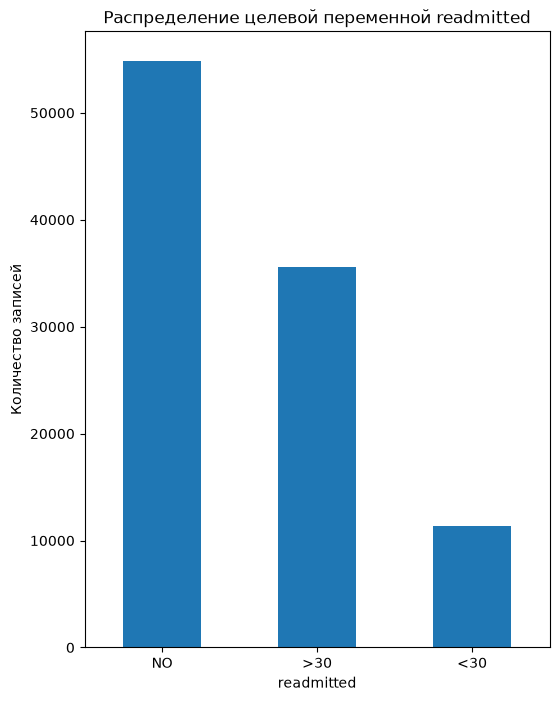

In [62]:
plt.figure(figsize=FIGSIZE)
df_raw["readmitted"].value_counts().plot(kind="bar")
plt.title("Распределение целевой переменной readmitted")
plt.ylabel("Количество записей")
plt.xticks(rotation=0)
plt.show()

Исходная переменная `readmitted` содержит три класса. В данной работе задача сведена к бинарной классификации: положительным классом считается `<30` (госпитализация в течение 30 дней), отрицательным - `>30` и `NO`. Это обосновано клинической значимостью 30-дневного порога как показателя качества медицинской помощи и соответствует постановке исходного исследования, для которого собирался датасет (Файл [description.pdf](https://www.kaggle.com/datasets/brandao/diabetes))

In [63]:
df_processed = df_raw.copy()

df_processed["target"] = (df_processed["readmitted"] == "<30").astype(int)

df_processed[["readmitted", "target"]].iloc[15:20]

,readmitted,target
15,NO,0
16,<30,1
17,NO,0
18,>30,0
19,NO,0


In [64]:
target_classes = df_processed["target"].value_counts(normalize=True)

target_classes

target
0    0.888401
1    0.111599
Name: proportion, dtype: float64

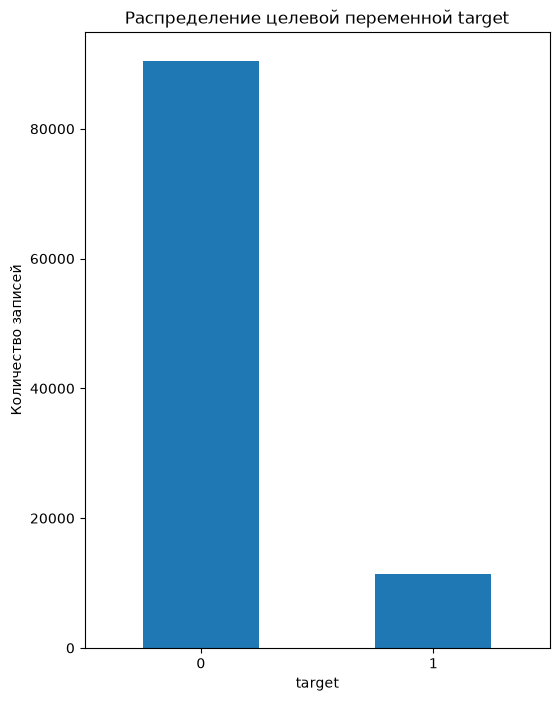

In [65]:
plt.figure(figsize=FIGSIZE)
df_processed["target"].value_counts().plot(kind="bar")
plt.title("Распределение целевой переменной target")
plt.ylabel("Количество записей")
plt.xticks(rotation=0)
plt.show()

В текущей задаче дисбаланс классов целевой переменной достигает 0.89/0.11

### Типы признаков

Тип признака определялся исходя из файла описания датасета, типа данных и уникальных значений

- `id_cols` - признаки с идентификаторами
- `num_cols` - количественные числовые признаки
- `ordinal_cols` - порядковые категориальные признаки
- `nominal_cols` - номинальные категориальные признаки

In [66]:
target_col = "target"

id_cols = ["encounter_id", "patient_nbr"]

num_cols = [
    "weight", "time_in_hospital", "num_lab_procedures", "num_procedures",
    "num_medications", "number_outpatient", "number_emergency",
    "number_inpatient", "number_diagnoses",
]

ordinal_cols = [
    "age", "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide", "citoglipton",
    "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone", "readmitted",
]

nominal_cols = [
    "race", "gender", "admission_type_id", "discharge_disposition_id", 
    "admission_source_id", "payer_code", "medical_specialty",
    "diag_1", "diag_2", "diag_3", "max_glu_serum", "A1Cresult",
    "change", "diabetesMed",
]

В дальнейшем, если признак будет удален, то необходимо также удалить его из этих списков признаков

In [67]:
def drop_column(df, col_name, verbose=False):
    lists = {"id_cols": id_cols, "num_cols": num_cols,
             "ordinal_cols": ordinal_cols, "nominal_cols": nominal_cols}

    removed_from = []
    for name, lst in lists.items():
        if col_name in lst:
            lst.remove(col_name)
            removed_from.append(name)

    if col_name in df.columns:
        df = df.drop(columns=[col_name])

    if verbose:
        print(f"Признак {col_name} удален")
        if removed_from:
            print(f"Признак {col_name} также удален из списков: {', '.join(removed_from)}")

    return df

`readmitted` уже можно удалить

In [68]:
df_processed = drop_column(df_processed, "readmitted", verbose=True)

Признак readmitted удален
Признак readmitted также удален из списков: ordinal_cols


### Кардинальность категориальных признаков

Кардинальность - число уникальных значений признака. Для категориальных признаков это ключевой параметр, определяющий способ кодирования.

- при 2–10 значениях можно использовать one-hot; при 100+ он дает тысячи почти нулевых колонок, из-за чего возникают большая размерность и переобучение.

- редкие категории (<1% строк) не несут надежного сигнала. обычно их переопределяют в "Other" или группируют по смыслу.

- высокая кардинальность делает матрицу разреженной в линейных моделях, что сказывается на результатах обучения.

Поэтому считаем nunique по ordinal_cols и nominal_cols, смотрим распределение частот и долю редких категорий и решаем, как и что кодировать

In [69]:
cat_cols_df = df_processed[ordinal_cols + nominal_cols]

nunique_df = cat_cols_df.nunique()

nunique_df

age                          10
metformin                     4
repaglinide                   4
nateglinide                   4
chlorpropamide                4
glimepiride                   4
acetohexamide                 2
glipizide                     4
glyburide                     4
tolbutamide                   2
pioglitazone                  4
rosiglitazone                 4
acarbose                      4
miglitol                      4
troglitazone                  2
tolazamide                    3
examide                       1
citoglipton                   1
insulin                       4
glyburide-metformin           4
glipizide-metformin           2
glimepiride-pioglitazone      2
metformin-rosiglitazone       2
metformin-pioglitazone        2
race                          5
gender                        3
admission_type_id             8
discharge_disposition_id     26
admission_source_id          17
payer_code                   17
medical_specialty            72
diag_1  

Выведем константные признаки. Их нужно будет удалить, они не имеют никакого смысла для модели

In [70]:
nunique_df[nunique_df == 1]

examide        1
citoglipton    1
dtype: int64

In [71]:
df_processed = drop_column(df_processed, "examide", verbose=True)

df_processed = drop_column(df_processed, "citoglipton", verbose=True)

Признак examide удален
Признак examide также удален из списков: ordinal_cols
Признак citoglipton удален
Признак citoglipton также удален из списков: ordinal_cols


Для бинарных признаков можно посмотреть баланс классов, чтобы удалить признаки, где огромная доля принадлежит данным одного класса

In [72]:
binary_cols = nunique_df[nunique_df == 2]

binary_cols

acetohexamide               2
tolbutamide                 2
troglitazone                2
glipizide-metformin         2
glimepiride-pioglitazone    2
metformin-rosiglitazone     2
metformin-pioglitazone      2
change                      2
diabetesMed                 2
dtype: int64

In [73]:
for col in binary_cols.index.tolist():
    print(f"{col}. Абсолютные значения")
    print(df_processed[col].value_counts().to_string())
    print(f"{col}. Относительные значения")
    print(df_processed[col].value_counts(normalize=True).to_string())

acetohexamide. Абсолютные значения
acetohexamide
No        101765
Steady         1
acetohexamide. Относительные значения
acetohexamide
No        0.99999
Steady    0.00001
tolbutamide. Абсолютные значения
tolbutamide
No        101743
Steady        23
tolbutamide. Относительные значения
tolbutamide
No        0.999774
Steady    0.000226
troglitazone. Абсолютные значения
troglitazone
No        101763
Steady         3
troglitazone. Относительные значения
troglitazone
No        0.999971
Steady    0.000029
glipizide-metformin. Абсолютные значения
glipizide-metformin
No        101753
Steady        13
glipizide-metformin. Относительные значения
glipizide-metformin
No        0.999872
Steady    0.000128
glimepiride-pioglitazone. Абсолютные значения
glimepiride-pioglitazone
No        101765
Steady         1
glimepiride-pioglitazone. Относительные значения
glimepiride-pioglitazone
No        0.99999
Steady    0.00001
metformin-rosiglitazone. Абсолютные значения
metformin-rosiglitazone
No        1017

Признаки, близкие к константным (от 1 до 23 наблюдений на 101766 строк) тоже надо удалить, модель не сможет понять зависимость, это будет шумом

In [74]:
cols_to_drop = [
    'acetohexamide', 'tolbutamide', 'troglitazone',
    'glipizide-metformin', 'glimepiride-pioglitazone',
    'metformin-rosiglitazone', 'metformin-pioglitazone',
]

for col in cols_to_drop:
    df_processed = drop_column(df_processed, col, verbose=True)

Признак acetohexamide удален
Признак acetohexamide также удален из списков: ordinal_cols
Признак tolbutamide удален
Признак tolbutamide также удален из списков: ordinal_cols
Признак troglitazone удален
Признак troglitazone также удален из списков: ordinal_cols
Признак glipizide-metformin удален
Признак glipizide-metformin также удален из списков: ordinal_cols
Признак glimepiride-pioglitazone удален
Признак glimepiride-pioglitazone также удален из списков: ordinal_cols
Признак metformin-rosiglitazone удален
Признак metformin-rosiglitazone также удален из списков: ordinal_cols
Признак metformin-pioglitazone удален
Признак metformin-pioglitazone также удален из списков: ordinal_cols


In [75]:
many_categories = nunique_df[nunique_df > TOP_N_UNIQUE_CATEGORIES]
many_categories

discharge_disposition_id     26
admission_source_id          17
payer_code                   17
medical_specialty            72
diag_1                      716
diag_2                      748
diag_3                      789
dtype: int64

Для признаков `payer_code` и `medical_specialty` можно применить подход: оставляем значения с наибольшим количеством наблюдений, остальные заменяем на `Other`

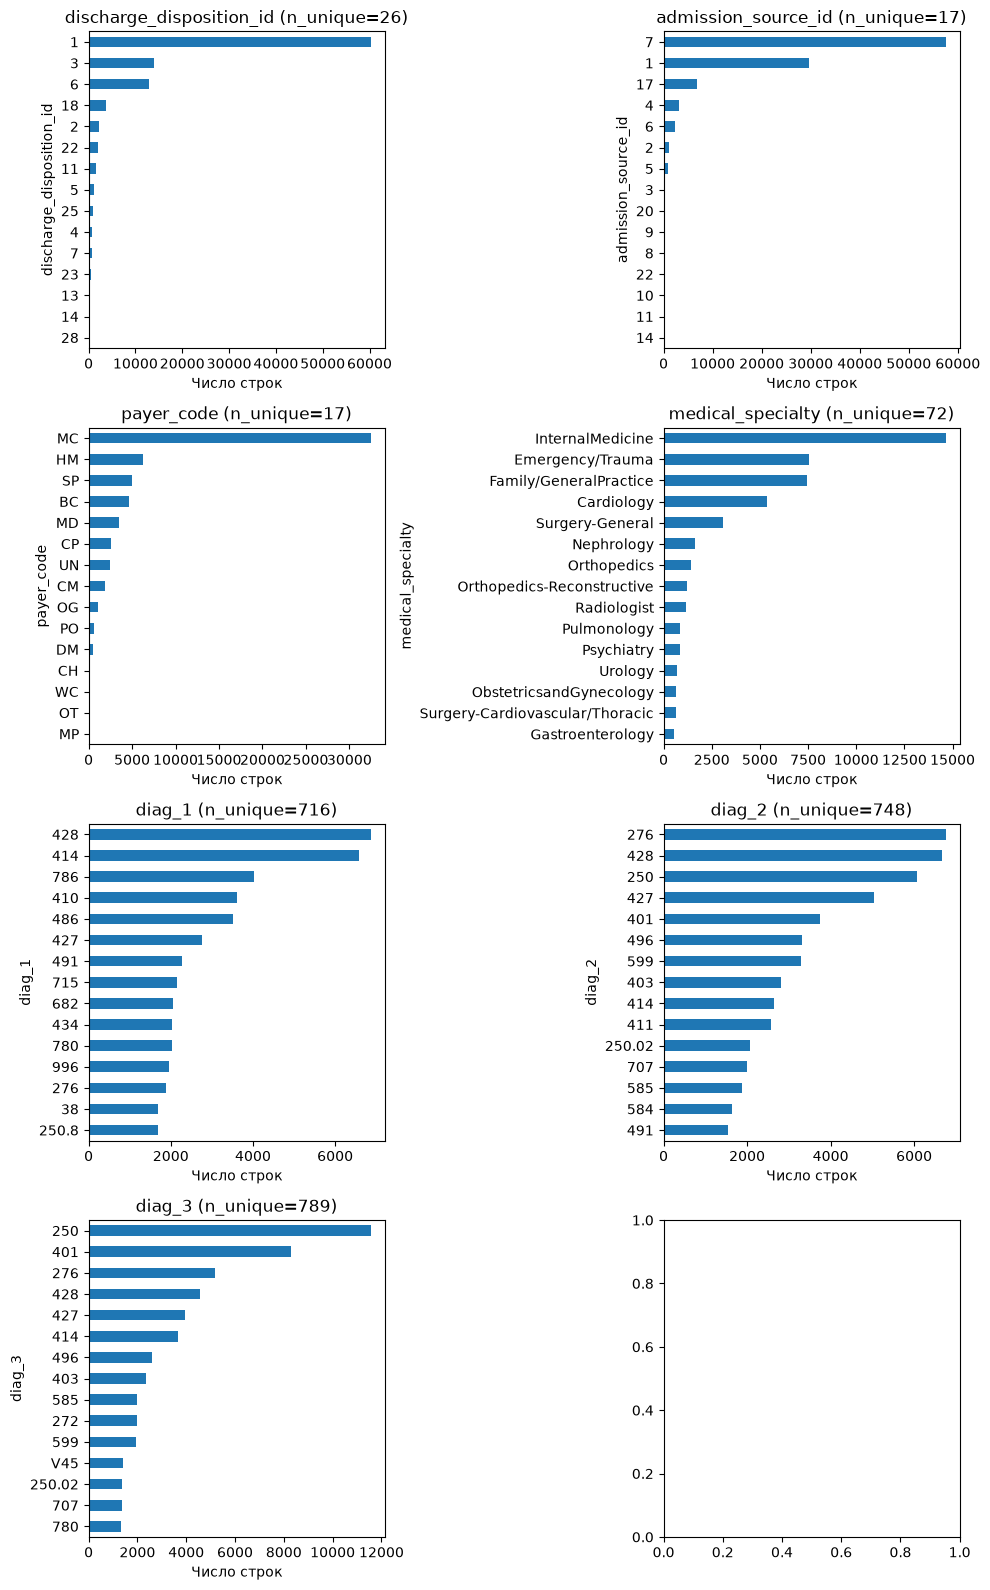

In [76]:
cols = many_categories.index.tolist()
n = len(cols)
ncols = 2
if n % ncols == 0:
    nrows = n // ncols
else:
    nrows = n // ncols + 1

fig, axes = plt.subplots(nrows, ncols, figsize=(10, 4 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, cols):
    vc = df_processed[col].value_counts().head(TOP_N_UNIQUE_CATEGORIES).sort_values()
    vc.plot(kind="barh", ax=ax)
    ax.set_title(f"{col} (n_unique={df_processed[col].nunique()})")
    ax.set_xlabel("Число строк")
    ax.tick_params(axis="y")

plt.tight_layout()
plt.show()

In [77]:
def add_other_category(df, col_name, top_n):
    top_n_df = df[col_name].value_counts().head(top_n).index
    return df[col_name].where(df[col_name].isin(top_n_df), "Other")

In [78]:
df_processed["medical_specialty"] = add_other_category(df_processed, "medical_specialty", 9)

df_processed["payer_code"] = add_other_category(df_processed, "payer_code", 8)

`diag_1/2/3` - это диагнозы, закодированные в МКБ-9 (ICD-9): трехзначные коды вроде 428 (сердечная недостаточность), 250 (диабет). Таких кодов в датасете 716–789 уникальных значений на каждую колонку. Если закодировать их с помощью one-hot-encoder, получится очень много признаков.

Напишем функцию, которая сворачивает конкретный код в главу МКБ-9, крупную группу болезней. Названия взяты с [сайта](https://ru.everybodywiki.com/%D0%A1%D0%BF%D0%B8%D1%81%D0%BE%D0%BA_%D0%BA%D0%BE%D0%B4%D0%BE%D0%B2_%D0%9C%D0%9A%D0%91-9)

В результате кардинальность падает

In [79]:
bins   = [
    0, 139, 239, 279, 289, 319,
    389, 459, 519, 579,
    629, 679, 709, 739, 
    759, 779, 799, 999
]
labels = [
    "Infectious", "Neoplasms", "Endocrine", "Blood", "Mental",
    "Nervous", "Circulatory", "Respiratory", "Digestive",
    "Genitourinary", "Pregnancy", "Skin", "Musculoskeletal",
    "Congenital", "Perinatal", "Symptoms", "Injury"
]

In [80]:
def group_diag_series(s):
    s = s.astype(str)
    # V/E-коды и нечисловые - отдельно
    is_external = s.str.startswith(("V", "E"))
    num = pd.to_numeric(s, errors="coerce")
    is_diabetes = (num >= 250) & (num < 251)

    result = pd.cut(num, bins=bins, labels=labels, right=True).astype("object")
    result[is_diabetes] = "Diabetes"
    result[is_external] = "External"
    result[num.isna() & ~is_external] = "Other"
    result[s == "Unknown"] = "Unknown"
    return result

In [81]:
for c in ["diag_1", "diag_2", "diag_3"]:
    df_processed[c] = group_diag_series(df_processed[c])

df_processed[["diag_1", "diag_2", "diag_3"]]

,diag_1,diag_2,diag_3
0,Diabetes,Other,Other
1,Endocrine,Diabetes,Endocrine
2,Pregnancy,Diabetes,External
3,Infectious,Diabetes,Circulatory
4,Neoplasms,Neoplasms,Diabetes
...,...,...,...
101761,Diabetes,Mental,Circulatory
101762,Digestive,Endocrine,Symptoms
101763,Infectious,Genitourinary,Mental
101764,Injury,Blood,Injury


### Визуализация пропусков

Посмотрим долю пропусков по столбцам

In [82]:
df_processed.isna().mean().loc[lambda s: s > 0].sort_values(ascending=False)

weight           0.968585
max_glu_serum    0.947468
A1Cresult        0.832773
race             0.022336
dtype: float64

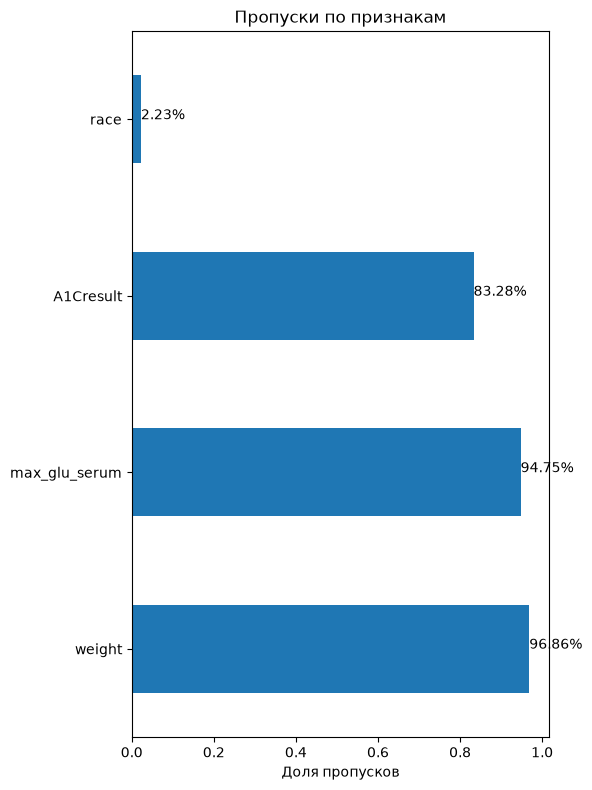

In [83]:
missings = df_processed.isna().mean().sort_values(ascending=False)
missings = missings[missings > 0]

plt.figure(figsize=FIGSIZE)
missings.plot(kind="barh")
plt.xlabel("Доля пропусков")
plt.title("Пропуски по признакам")

for i, v in enumerate(missings.values):
    plt.text(v, i, f"{v:.2%}")

plt.tight_layout()
plt.show()

Пропуски в `max_glu_serum` и `A1Cresult` не являются случайными: они означают, что соответствующий анализ не был назначен. Это значимая информация, поэтому пропуски кодируются отдельной категорией `NotMeasured`, а не заполняются модой/медианой. Для race используется категория `Unknown`. Признак `weight` можно удалить, вместо него сделать бинарный признак `weight_measured`

In [84]:
df_processed["race"] = df_processed["race"].fillna("Unknown")
df_processed["max_glu_serum"] = df_processed["max_glu_serum"].fillna("NotMeasured")
df_processed["A1Cresult"] = df_processed["A1Cresult"].fillna("NotMeasured")

df_processed["glu_measured"] = (df_processed["max_glu_serum"] != "NotMeasured").astype(int)
df_processed["a1c_measured"] = (df_processed["A1Cresult"] != "NotMeasured").astype(int)

df_processed["weight_measured"] = df_processed["weight"].notna().astype(int)
df_processed = drop_column(df_processed, "weight", verbose=True)

df_processed[["race", "max_glu_serum", "A1Cresult", "glu_measured", "a1c_measured", "weight_measured"]]

Признак weight удален
Признак weight также удален из списков: num_cols


,race,max_glu_serum,A1Cresult,glu_measured,a1c_measured,weight_measured
0,Caucasian,NotMeasured,NotMeasured,0,0,0
1,Caucasian,NotMeasured,NotMeasured,0,0,0
2,AfricanAmerican,NotMeasured,NotMeasured,0,0,0
3,Caucasian,NotMeasured,NotMeasured,0,0,0
4,Caucasian,NotMeasured,NotMeasured,0,0,0
...,...,...,...,...,...,...
101761,AfricanAmerican,NotMeasured,>8,0,1,0
101762,AfricanAmerican,NotMeasured,NotMeasured,0,0,0
101763,Caucasian,NotMeasured,NotMeasured,0,0,0
101764,Caucasian,NotMeasured,NotMeasured,0,0,0


In [85]:
df_processed.to_csv("../data/processed/diabetic_data_processed.csv", index=False)